# Experiment 013: completed 7B phase 2 analysis plots

This notebook checks the completed 7B seed 1 and base-to-GRPO runs, then
cross-references them with Phase 1 and the earlier A100 scale experiments.
Generative exact match stays primary and the letter probe stays diagnostic.

The registered 7B SFT-to-GRPO endpoint now has two seeds. The direct route
comparison stays a matched seed-0 result because base-to-GRPO has one seed.
Figures are saved to `analysis/figures/013_2/`.


In [1]:
# load the completed 013 runs and matched A100 comparisons
import json
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import numpy as np
import pandas as pd
from IPython.display import display
get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'config.py').exists():
    raise FileNotFoundError('repository root containing config.py was not found')
sys.path.insert(0, str(ROOT))

from analysis.plotting import heatmap_text_color
from analysis.stats import align_pred_rows, holm, mcnemar_exact, paired_delta_ci
from data.subjects import TIERS as VALIDATED_TIERS

RES = ROOT / 'results'
BASE13 = RES / 'base_evals' / '013_COLAB_FULL_B7'
RUN13_WARM = {
    0: RES / '013_COLAB_FULL_B7_sft_grpo_seed0',
    1: RES / '013_COLAB_FULL_B7_sft_grpo_seed1',
}
RUN13_BASE = RES / '013_COLAB_FULL_B7_base_grpo_seed0'
FIG = ROOT / 'analysis' / 'figures' / '013_2'
FIG.mkdir(parents=True, exist_ok=True)

SCALE_SPECS = {
    '0.5B': {
        'params': 0.5, 'code': 'B05', 'warm_exp': '006', 'warm_seeds': (0, 1, 2),
        'base_exp': '005',
    },
    '1.5B': {
        'params': 1.5, 'code': 'B15', 'warm_exp': '009', 'warm_seeds': (0, 1),
        'base_exp': '012',
    },
    '3B': {
        'params': 3.0, 'code': 'B3', 'warm_exp': '003', 'warm_seeds': (0, 1),
        'base_exp': '004',
    },
    '7B': {
        'params': 7.0, 'code': 'B7', 'warm_exp': '013', 'warm_seeds': (0, 1),
        'base_exp': '013',
    },
}

plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {
    'base': '#4C78A8', 'sft': '#54A24B', 'warm0': '#F58518',
    'warm1': '#E45756', 'base_grpo': '#72B7B2', 'probe': '#9D9DA1',
}
TIER_COLORS = {
    'easy': '#59A14F', 'medium': '#F28E2B',
    'hard': '#E15759', 'overall': '#4C4C4C',
}
RUN_COLORS = {
    'SFT + GRPO seed 0': COLORS['warm0'],
    'SFT + GRPO seed 1': COLORS['warm1'],
    'base + GRPO seed 0': COLORS['base_grpo'],
}
TIERS = ['easy', 'medium', 'hard']
GROUPS = TIERS + ['overall']
TIER_LOOKUP = {
    subject: tier for tier, subjects in VALIDATED_TIERS.items() for subject in subjects
}
SUBJECTS = [subject for tier in TIERS for subject in VALIDATED_TIERS[tier]]

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        rows = [json.loads(line) for line in handle if line.strip()]
    return [{**row, 'tier': TIER_LOOKUP[row['subject']]} for row in rows]

def raw_jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def series(trainlog, key):
    rows = [row for row in trainlog if key in row and 'step' in row]
    return (
        np.asarray([row['step'] for row in rows]),
        np.asarray([row[key] for row in rows], dtype=float),
    )

def smooth(values, window=20):
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window) / window, mode='valid')

def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=300, bbox_inches='tight')
    print('saved', name)

def accuracy(rows):
    return float(np.mean([bool(row['correct']) for row in rows]))

def group_rows(rows, group):
    return rows if group == 'overall' else [row for row in rows if row['tier'] == group]

def group_accuracy(rows, group):
    return accuracy(group_rows(rows, group))

def paired_correct(rows_a, rows_b, group='overall'):
    rows_a, rows_b = align_pred_rows(rows_a, rows_b)
    if group != 'overall':
        rows_a = [row for row in rows_a if row['tier'] == group]
        rows_b = [row for row in rows_b if row['tier'] == group]
    if len(rows_a) != len(rows_b):
        raise ValueError('paired prediction counts differ')
    return [bool(row['correct']) for row in rows_a], [bool(row['correct']) for row in rows_b]

def paired_stats(rows_a, rows_b, seed):
    output = []
    for index, group in enumerate(GROUPS):
        correct_a, correct_b = paired_correct(rows_a, rows_b, group)
        delta, lo, hi = paired_delta_ci(correct_a, correct_b, seed=seed + index)
        a_only = sum(a and not b for a, b in zip(correct_a, correct_b))
        b_only = sum((not a) and b for a, b in zip(correct_a, correct_b))
        output.append({
            'group': group,
            'delta': delta,
            'ci_lo': lo,
            'ci_hi': hi,
            'reference_only_correct': a_only,
            'grpo_only_correct': b_only,
            'mcnemar_p': mcnemar_exact(a_only, b_only),
        })
    adjusted = holm([row['mcnemar_p'] for row in output[:3]])
    for row, value in zip(output[:3], adjusted):
        row['holm_p_tiers'] = value
    output[-1]['holm_p_tiers'] = np.nan
    return output

def nonfinite_paths(value, path='root'):
    found = []
    if isinstance(value, dict):
        for key, item in value.items():
            found.extend(nonfinite_paths(item, f'{path}/{key}'))
    elif isinstance(value, list):
        for index, item in enumerate(value):
            found.extend(nonfinite_paths(item, f'{path}/{index}'))
    elif isinstance(value, float) and not math.isfinite(value):
        found.append(path)
    return found

def load_warm(run_dir):
    return {
        's': jload(run_dir / 'sft_trainlog.json'),
        'g': jload(run_dir / 'grpo_trainlog.json'),
        'eval': {
            'base': jload(BASE13 / 'base_eval.json'),
            'sft': jload(run_dir / 'sft_eval.json'),
            'grpo': jload(run_dir / 'grpo_eval.json'),
        },
        'lp': {
            'base': jload(BASE13 / 'base_logprob.json'),
            'sft': jload(run_dir / 'sft_logprob.json'),
            'grpo': jload(run_dir / 'grpo_logprob.json'),
        },
        'preds': {
            'base': jsonl(BASE13 / 'base_preds.jsonl'),
            'sft': jsonl(run_dir / 'sft_preds.jsonl'),
            'grpo': jsonl(run_dir / 'grpo_preds.jsonl'),
        },
        'lp_preds': {
            'base': jsonl(BASE13 / 'base_logprob_preds.jsonl'),
            'sft': jsonl(run_dir / 'sft_logprob_preds.jsonl'),
            'grpo': jsonl(run_dir / 'grpo_logprob_preds.jsonl'),
        },
        'man': jload(run_dir / 'manifest.json'),
        'summary': jload(run_dir / 'summary.json'),
        'log': (run_dir / 'run.log').read_text(),
    }

def load_base_route(run_dir):
    return {
        'g': jload(run_dir / 'grpo_trainlog.json'),
        'eval': {
            'base': jload(BASE13 / 'base_eval.json'),
            'grpo': jload(run_dir / 'grpo_eval.json'),
        },
        'lp': {
            'base': jload(BASE13 / 'base_logprob.json'),
            'grpo': jload(run_dir / 'grpo_logprob.json'),
        },
        'preds': {
            'base': jsonl(BASE13 / 'base_preds.jsonl'),
            'grpo': jsonl(run_dir / 'grpo_preds.jsonl'),
        },
        'lp_preds': {
            'base': jsonl(BASE13 / 'base_logprob_preds.jsonl'),
            'grpo': jsonl(run_dir / 'grpo_logprob_preds.jsonl'),
        },
        'man': jload(run_dir / 'manifest.json'),
        'summary': jload(run_dir / 'summary.json'),
        'log': (run_dir / 'run.log').read_text(),
    }

WARM = {seed: load_warm(path) for seed, path in RUN13_WARM.items()}
BASE_ROUTE = load_base_route(RUN13_BASE)

for seed, data in WARM.items():
    assert max(row['step'] for row in data['s'] if 'step' in row) == 500
    assert len([row for row in data['g'] if 'reward' in row]) == 500
    assert all(data['eval'][stage]['n_items'] == 1884 for stage in ('base', 'sft', 'grpo'))
    assert all(len(data['preds'][stage]) == 1884 for stage in ('base', 'sft', 'grpo'))
    assert data['man']['model_id'] == 'Qwen/Qwen2.5-7B'
    assert data['man']['resolved_dtype'] == 'bfloat16'
    assert 'A100-SXM4-80GB' in data['man']['gpu']['device']
    assert data['man']['config']['exec']['allow_oom_fallback'] is False
    assert data['man']['git']['dirty'] is False
    assert data['log'].count('done. total wall time') == 1
    assert not any(term in data['log'].lower() for term in [
        'traceback', 'out of memory', 'protocol abort', 'keyboardinterrupt',
    ])

assert len([row for row in BASE_ROUTE['g'] if 'reward' in row]) == 500
assert all(BASE_ROUTE['eval'][stage]['n_items'] == 1884 for stage in ('base', 'grpo'))
assert all(len(BASE_ROUTE['preds'][stage]) == 1884 for stage in ('base', 'grpo'))
assert BASE_ROUTE['man']['model_id'] == 'Qwen/Qwen2.5-7B'
assert BASE_ROUTE['man']['resolved_dtype'] == 'bfloat16'
assert 'A100-SXM4-80GB' in BASE_ROUTE['man']['gpu']['device']
assert BASE_ROUTE['man']['config']['exec']['allow_oom_fallback'] is False
assert BASE_ROUTE['man']['git']['dirty'] is False
assert BASE_ROUTE['log'].count('done. total wall time') == 1
assert not any(term in BASE_ROUTE['log'].lower() for term in [
    'traceback', 'out of memory', 'protocol abort', 'keyboardinterrupt',
])

print('loaded and checked all three experiment 013 runs')
print('figures ->', FIG)


loaded and checked all three experiment 013 runs
figures -> /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/analysis/figures/013_2


## 1. Run health and completion

The process checks stay separate from the accuracy results. Both Phase 2 runs
must pass these checks before their endpoints are interpreted.


In [2]:
run_views = {
    'SFT + GRPO seed 0': WARM[0],
    'SFT + GRPO seed 1': WARM[1],
    'base + GRPO seed 0': BASE_ROUTE,
}
health_rows = []
window_rows = []
for label, data in run_views.items():
    reward_rows = [row for row in data['g'] if 'reward' in row and 'step' in row]
    invalid = nonfinite_paths(data['g'])
    if 's' in data:
        invalid += nonfinite_paths(data['s'])
    first = reward_rows[:50]
    last = reward_rows[-50:]
    health_rows.append({
        'run': label,
        'SFT steps': max([row['step'] for row in data.get('s', []) if 'step' in row], default=0),
        'GRPO steps': len(reward_rows),
        'eval items': data['eval']['grpo']['n_items'],
        'first-50 clipped ratio': np.mean([row['completions/clipped_ratio'] for row in first]),
        'last-50 KL': np.mean([row['kl'] for row in last]),
        'non-finite values': len(invalid),
        'peak VRAM GB': data['man']['gpu']['peak_vram_gb'],
        'recorded hours': sum(data['man']['timings_sec'].values()) / 3600,
    })
    for key, metric, divisor in [
        ('rewards/accuracy_reward/mean', 'accuracy reward', 1.0),
        ('rewards/format_reward/mean', 'full-format reward rate', 0.2),
        ('kl', 'KL', 1.0),
        ('frac_reward_zero_std', 'zero reward variation', 1.0),
        ('completions/mean_length', 'rollout mean length', 1.0),
        ('completions/clipped_ratio', 'clipped ratio', 1.0),
    ]:
        window_rows.append({
            'run': label,
            'metric': metric,
            'first 50': np.mean([row[key] for row in first]) / divisor,
            'last 50': np.mean([row[key] for row in last]) / divisor,
        })

health_tbl = pd.DataFrame(health_rows).set_index('run')
window_tbl = pd.DataFrame(window_rows)
window_tbl['change'] = window_tbl['last 50'] - window_tbl['first 50']
display(health_tbl.round(4))
display(window_tbl.set_index(['run', 'metric']).round(4))


,SFT steps,GRPO steps,eval items,first-50 clipped ratio,last-50 KL,non-finite values,peak VRAM GB,recorded hours
run,,,,,,,,
SFT + GRPO seed 0,500,500,1884,0.0150,0.0122,0,71.317,5.0318
SFT + GRPO seed 1,500,500,1884,0.0125,0.0099,0,71.317,4.4202
base + GRPO seed 0,0,500,1884,0.0575,0.0225,0,73.433,4.4579


first 50   last 50   change
run                metric                                              
SFT + GRPO seed 0  accuracy reward            0.7025    0.6925  -0.0100
                   full-format reward rate    0.9000    0.9625   0.0625
                   KL                         0.0009    0.0122   0.0113
                   zero reward variation      0.2400    0.5400   0.3000
                   rollout mean length      112.9025   89.8325 -23.0700
                   clipped ratio              0.0150    0.0175   0.0025
SFT + GRPO seed 1  accuracy reward            0.6900    0.7800   0.0900
                   full-format reward rate    0.8800    0.9600   0.0800
                   KL                         0.0017    0.0099   0.0081
                   zero reward variation      0.1000    0.4400   0.3400
                   rollout mean length       95.0675  101.4725   6.4050
                   clipped ratio              0.0125    0.0350   0.0225
base + GRPO seed 0 accuracy reward            0.6800    0.7275   0.0475
                   full-format reward rate    0.6150    0.9700   0.3550
                   KL                         0.0026    0.0225   0.0199
                   zero reward variation      0.0200    0.4000   0.3800
                   rollout mean length      193.3450  141.1675 -52.1775
                   clipped ratio              0.0575    0.0250  -0.0325

## 2. Training behaviour


saved fig01_training_rewards


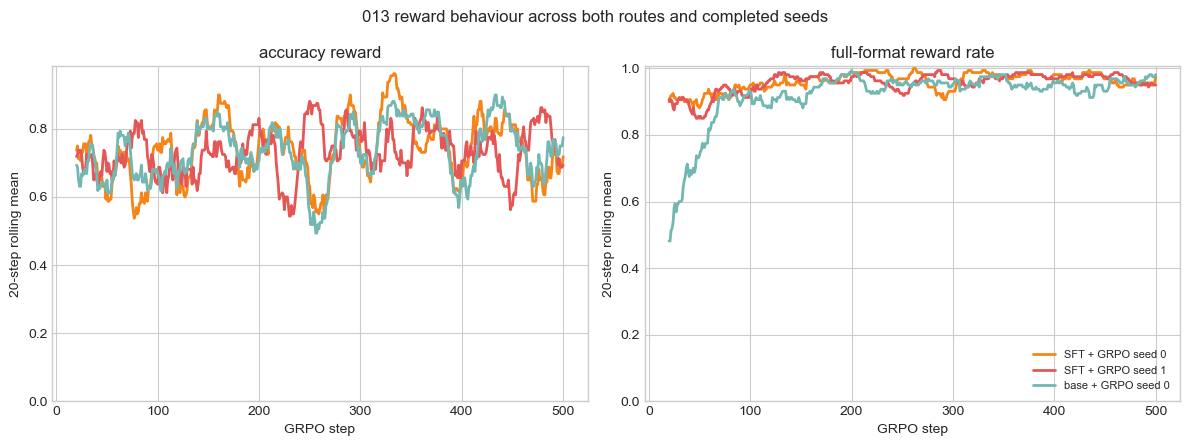

In [3]:
window = 20
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for label, data in run_views.items():
    for ax, key, title, divisor in [
        (axes[0], 'rewards/accuracy_reward/mean', 'accuracy reward', 1.0),
        (axes[1], 'rewards/format_reward/mean', 'full-format reward rate', 0.2),
    ]:
        x, values = series(data['g'], key)
        ax.plot(
            x[window - 1:],
            smooth(values / divisor, window),
            color=RUN_COLORS[label],
            lw=2,
            label=label,
        )
        ax.set_title(title)
        ax.set_xlabel('GRPO step')
        ax.set_ylabel('20-step rolling mean')
        ax.set_ylim(bottom=0)
axes[1].legend(fontsize=8, loc='lower right')
fig.suptitle('013 reward behaviour across both routes and completed seeds')
fig.tight_layout()
save(fig, 'fig01_training_rewards')
plt.show()


saved fig02_optimisation_health


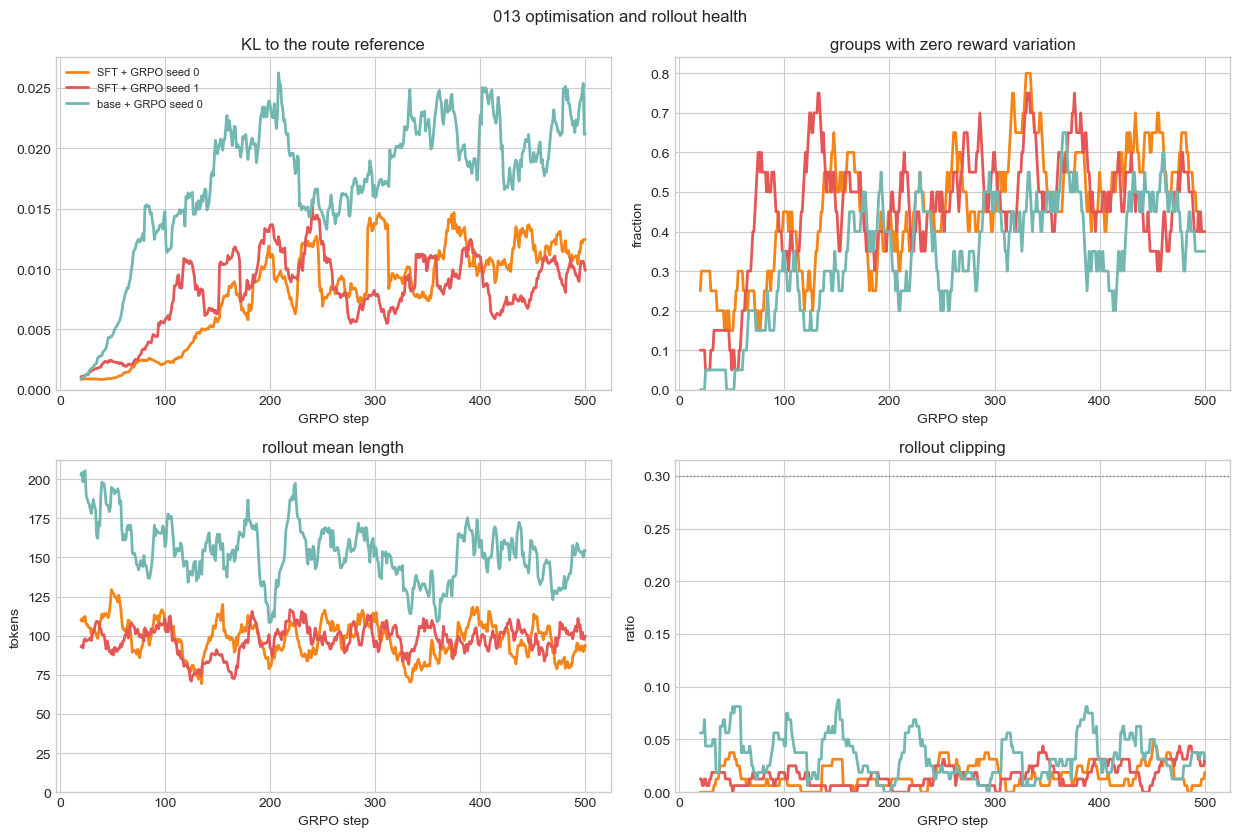

In [4]:
panels = [
    ('kl', 'KL to the route reference', None),
    ('frac_reward_zero_std', 'groups with zero reward variation', 'fraction'),
    ('completions/mean_length', 'rollout mean length', 'tokens'),
    ('completions/clipped_ratio', 'rollout clipping', 'ratio'),
]
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.5))
for ax, (key, title, ylabel) in zip(axes.flat, panels):
    for label, data in run_views.items():
        x, values = series(data['g'], key)
        ax.plot(
            x[window - 1:],
            smooth(values, window),
            color=RUN_COLORS[label],
            lw=2,
            label=label,
        )
    if key == 'completions/clipped_ratio':
        ax.axhline(0.3, color='grey', ls=':', lw=1, label='A1 threshold')
    ax.set_title(title)
    ax.set_xlabel('GRPO step')
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.set_ylim(bottom=0)
axes[0, 0].legend(fontsize=8)
fig.suptitle('013 optimisation and rollout health')
fig.tight_layout()
save(fig, 'fig02_optimisation_health')
plt.show()


saved fig03_sft_loss


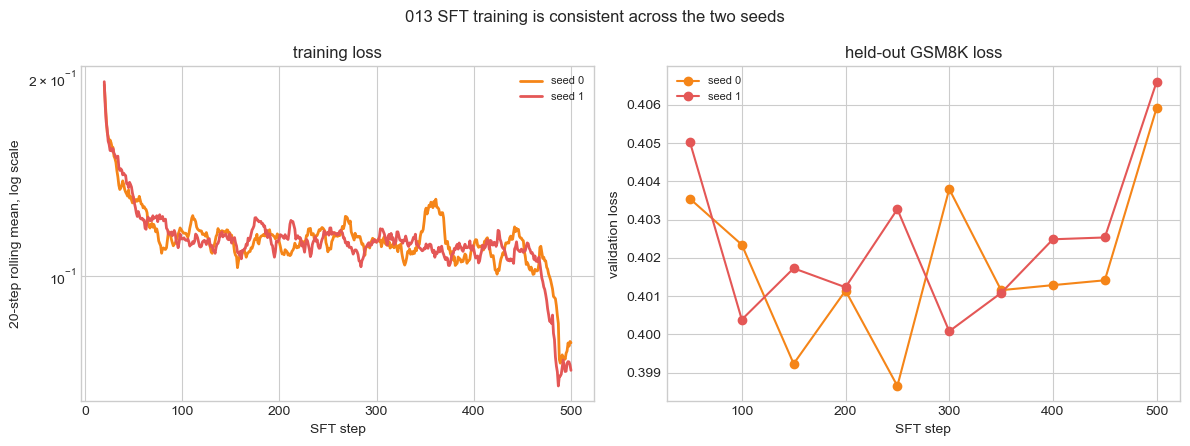

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for seed in (0, 1):
    label = f'seed {seed}'
    color = COLORS[f'warm{seed}']
    x, values = series(WARM[seed]['s'], 'loss')
    axes[0].plot(
        x[window - 1:],
        smooth(values, window),
        color=color,
        lw=2,
        label=label,
    )
    x, values = series(WARM[seed]['s'], 'eval_loss')
    axes[1].plot(x, values, 'o-', color=color, lw=1.5, label=label)
axes[0].set_yscale('log')
axes[0].set_title('training loss')
axes[0].set_ylabel('20-step rolling mean, log scale')
axes[1].set_title('held-out GSM8K loss')
axes[1].set_ylabel('validation loss')
for ax in axes:
    ax.set_xlabel('SFT step')
    ax.legend(fontsize=8)
fig.suptitle('013 SFT training is consistent across the two seeds')
fig.tight_layout()
save(fig, 'fig03_sft_loss')
plt.show()


## 3. Completed 7B endpoint

The two SFT-to-GRPO seeds complete the registered 7B primary endpoint.
Base-to-GRPO remains the planned one-seed route comparison.


mean     min     max  n
group   condition                             
easy    base         0.8692  0.8692  0.8692  1
        GSM8K SFT    0.8800  0.8783  0.8817  2
        SFT + GRPO   0.8925  0.8919  0.8931  2
        base + GRPO  0.8885  0.8885  0.8885  1
medium  base         0.7356  0.7356  0.7356  1
        GSM8K SFT    0.7553  0.7537  0.7570  2
        SFT + GRPO   0.7767  0.7767  0.7767  2
        base + GRPO  0.7635  0.7635  0.7635  1
hard    base         0.5960  0.5960  0.5960  1
        GSM8K SFT    0.5922  0.5884  0.5960  2
        SFT + GRPO   0.6477  0.6389  0.6566  2
        base + GRPO  0.6540  0.6540  0.6540  1
overall base         0.7686  0.7686  0.7686  1
        GSM8K SFT    0.7792  0.7787  0.7797  2
        SFT + GRPO   0.8036  0.8020  0.8052  2
        base + GRPO  0.7988  0.7988  0.7988  1

saved fig04_completed_endpoint


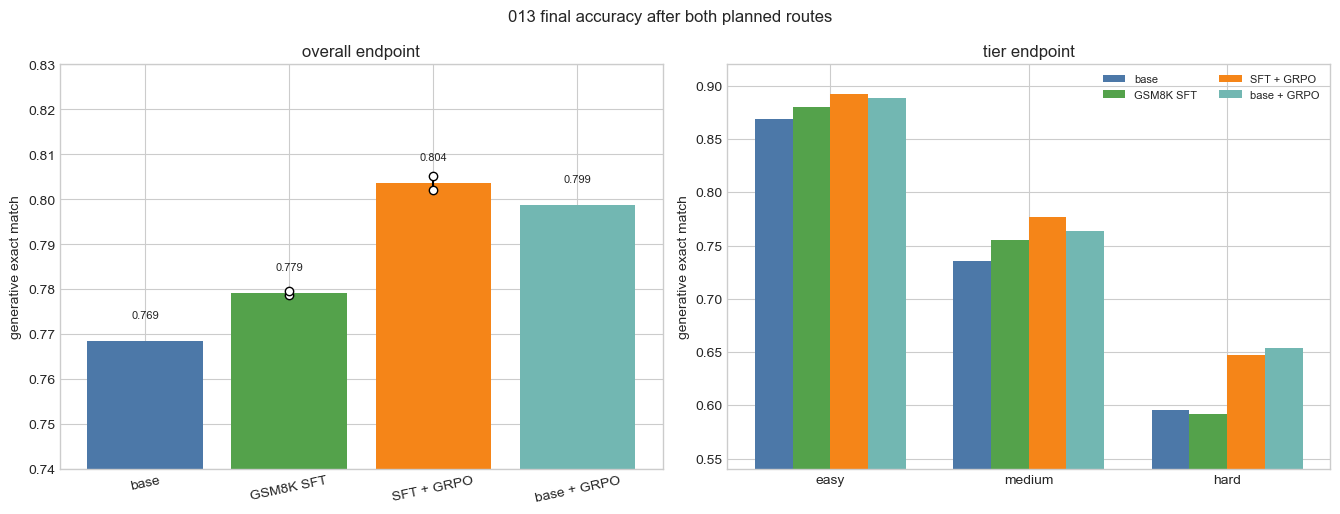

In [6]:
endpoint_rows = []
for group in GROUPS:
    base_value = group_accuracy(WARM[0]['preds']['base'], group)
    sft_values = [group_accuracy(WARM[seed]['preds']['sft'], group) for seed in (0, 1)]
    warm_values = [group_accuracy(WARM[seed]['preds']['grpo'], group) for seed in (0, 1)]
    base_grpo_value = group_accuracy(BASE_ROUTE['preds']['grpo'], group)
    endpoint_rows.extend([
        {'group': group, 'condition': 'base', 'mean': base_value, 'min': base_value, 'max': base_value, 'n': 1},
        {'group': group, 'condition': 'GSM8K SFT', 'mean': np.mean(sft_values), 'min': min(sft_values), 'max': max(sft_values), 'n': 2},
        {'group': group, 'condition': 'SFT + GRPO', 'mean': np.mean(warm_values), 'min': min(warm_values), 'max': max(warm_values), 'n': 2},
        {'group': group, 'condition': 'base + GRPO', 'mean': base_grpo_value, 'min': base_grpo_value, 'max': base_grpo_value, 'n': 1},
    ])
endpoint_tbl = pd.DataFrame(endpoint_rows)
display(endpoint_tbl.set_index(['group', 'condition']).round(4))

conditions = ['base', 'GSM8K SFT', 'SFT + GRPO', 'base + GRPO']
condition_colors = [COLORS['base'], COLORS['sft'], COLORS['warm0'], COLORS['base_grpo']]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
overall = endpoint_tbl.query("group == 'overall'").set_index('condition').loc[conditions]
x = np.arange(len(conditions))
bars = axes[0].bar(x, overall['mean'], color=condition_colors)
for index, row in enumerate(overall.itertuples()):
    if row.n > 1:
        axes[0].plot([index, index], [row.min, row.max], color='black', lw=1.5)
        axes[0].scatter([index, index], [row.min, row.max], color='white', edgecolor='black', zorder=3)
    axes[0].text(index, row.mean + 0.005, f'{row.mean:.3f}', ha='center', fontsize=8)
axes[0].set_xticks(x)
axes[0].set_xticklabels(conditions, rotation=12)
axes[0].set_ylim(0.74, 0.83)
axes[0].set_ylabel('generative exact match')
axes[0].set_title('overall endpoint')

width = 0.19
for index, condition in enumerate(conditions):
    values = [
        endpoint_tbl.query('group == @group and condition == @condition')['mean'].iloc[0]
        for group in TIERS
    ]
    axes[1].bar(
        np.arange(len(TIERS)) + (index - 1.5) * width,
        values,
        width,
        color=condition_colors[index],
        label=condition,
    )
axes[1].set_xticks(np.arange(len(TIERS)))
axes[1].set_xticklabels(TIERS)
axes[1].set_ylim(0.54, 0.92)
axes[1].set_ylabel('generative exact match')
axes[1].set_title('tier endpoint')
axes[1].legend(fontsize=8, ncol=2)
fig.suptitle('013 final accuracy after both planned routes')
fig.tight_layout()
save(fig, 'fig04_completed_endpoint')
plt.show()


delta     ci_lo     ci_hi  \
run                group                                   
SFT + GRPO seed 0  easy     0.011377 -0.004551  0.027304   
                   medium   0.019704 -0.003284  0.041051   
                   hard     0.050505  0.002525  0.098485   
                   overall  0.022293  0.007962  0.036624   
SFT + GRPO seed 1  easy     0.013652 -0.001138  0.028441   
                   medium   0.022989  0.001642  0.044335   
                   hard     0.060606  0.015152  0.108586   
                   overall  0.026539  0.012739  0.040340   
base + GRPO seed 0 easy     0.019340  0.001138  0.038680   
                   medium   0.027915 -0.001642  0.057471   
                   hard     0.058081  0.010101  0.106061   
                   overall  0.030255  0.013800  0.046709   

                            reference_only_correct  grpo_only_correct  \
run                group                                                
SFT + GRPO seed 0  easy                         19                 29   
                   medium                       18                 30   
                   hard                         38                 58   
                   overall                      75                117   
SFT + GRPO seed 1  easy                         16                 28   
                   medium                       16                 30   
                   hard                         33                 57   
                   overall                      65                115   
base + GRPO seed 0 easy                         28                 45   
                   medium                       36                 53   
                   hard                         35                 58   
                   overall                      99                156   

                            mcnemar_p  holm_p_tiers  
run                group                             
SFT + GRPO seed 0  easy      0.193413      0.222806  
                   medium    0.111403      0.222806  
                   hard      0.051911      0.155732  
                   overall   0.002987           NaN  
SFT + GRPO seed 1  easy      0.096142      0.108152  
                   medium    0.054076      0.108152  
                   hard      0.014867      0.044600  
                   overall   0.000239           NaN  
base + GRPO seed 0 easy      0.060370      0.120740  
                   medium    0.089321      0.120740  
                   hard      0.022019      0.066056  
                   overall   0.000431           NaN

saved fig05_paired_grpo_effects


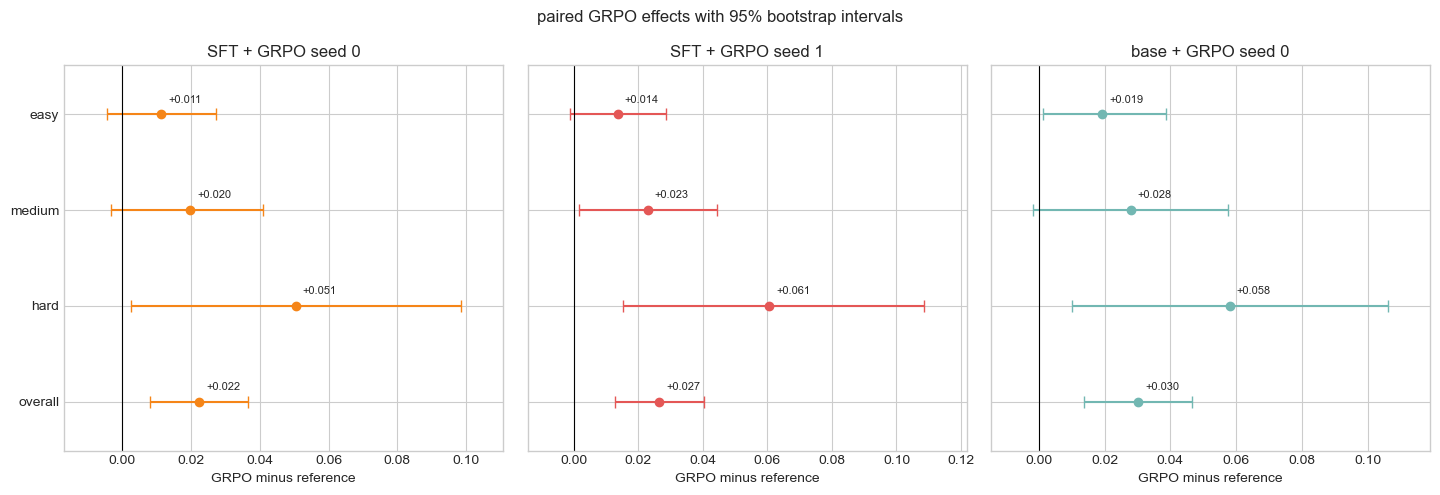

In [7]:
PAIR_RESULTS = {
    'SFT + GRPO seed 0': paired_stats(WARM[0]['preds']['sft'], WARM[0]['preds']['grpo'], seed=1400),
    'SFT + GRPO seed 1': paired_stats(WARM[1]['preds']['sft'], WARM[1]['preds']['grpo'], seed=1500),
    'base + GRPO seed 0': paired_stats(BASE_ROUTE['preds']['base'], BASE_ROUTE['preds']['grpo'], seed=1600),
}
paired_tbl = pd.concat(
    [pd.DataFrame(rows).assign(run=label) for label, rows in PAIR_RESULTS.items()],
    ignore_index=True,
).set_index(['run', 'group'])
display(paired_tbl.round(6))

fig, axes = plt.subplots(1, 3, figsize=(14.5, 5), sharey=True)
for ax, (label, rows) in zip(axes, PAIR_RESULTS.items()):
    table = pd.DataFrame(rows).set_index('group').loc[GROUPS]
    y = np.arange(len(GROUPS))
    values = table['delta'].to_numpy()
    errors = [values - table['ci_lo'].to_numpy(), table['ci_hi'].to_numpy() - values]
    ax.errorbar(values, y, xerr=errors, fmt='o', capsize=4, color=RUN_COLORS[label])
    ax.axvline(0, color='black', lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels(GROUPS)
    ax.invert_yaxis()
    ax.set_xlabel('GRPO minus reference')
    ax.set_title(label)
    ax.margins(x=0.12, y=0.17)
    for position, value in zip(y, values):
        ax.annotate(f'{value:+.3f}', (value, position), xytext=(5 if value >= 0 else -5, 7),
                    textcoords='offset points', ha='left' if value >= 0 else 'right',
                    va='bottom', fontsize=8)
fig.suptitle('paired GRPO effects with 95% bootstrap intervals')
fig.tight_layout()
save(fig, 'fig05_paired_grpo_effects')
plt.show()


## 4. Does the GSM8K warm start matter at 7B?


,delta,ci_lo,ci_hi,reference_only_correct,grpo_only_correct,mcnemar_p,holm_p_tiers
group,,,,,,,
easy,0.004551,-0.012514,0.021615,29,33,0.703537,1.0
medium,0.013136,-0.016420,0.042693,40,48,0.455741,1.0
hard,-0.015152,-0.068182,0.037879,63,57,0.648260,1.0
overall,0.003185,-0.013800,0.020170,132,138,0.760972,NaN


saved fig06_warm_start_route_difference


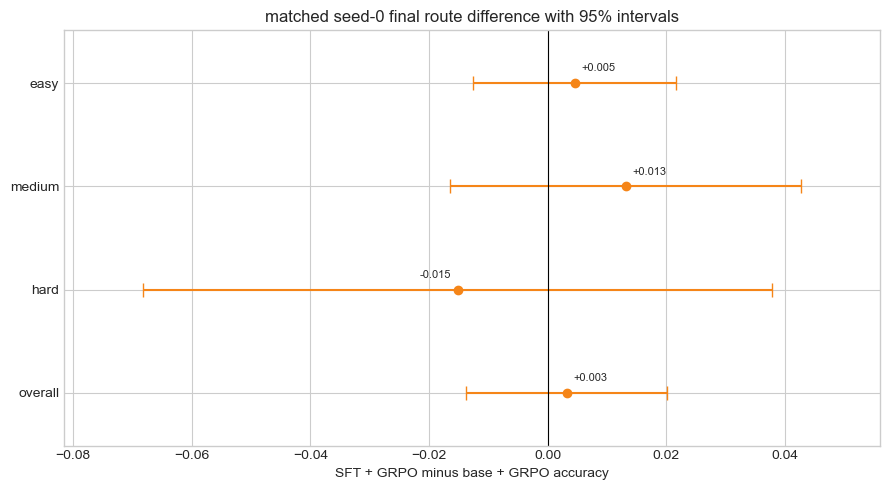

In [8]:
ROUTE_STATS = paired_stats(
    BASE_ROUTE['preds']['grpo'],
    WARM[0]['preds']['grpo'],
    seed=1700,
)
route_stats_tbl = pd.DataFrame(ROUTE_STATS).set_index('group').loc[GROUPS]
display(route_stats_tbl.round(6))

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(GROUPS))
values = route_stats_tbl['delta'].to_numpy()
errors = [
    values - route_stats_tbl['ci_lo'].to_numpy(),
    route_stats_tbl['ci_hi'].to_numpy() - values,
]
ax.errorbar(values, y, xerr=errors, fmt='o', capsize=5, color=COLORS['warm0'])
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(GROUPS)
ax.invert_yaxis()
ax.set_xlabel('SFT + GRPO minus base + GRPO accuracy')
ax.set_title('matched seed-0 final route difference with 95% intervals')
ax.margins(x=0.12, y=0.17)
for position, value in zip(y, values):
    ax.annotate(f'{value:+.3f}', (value, position), xytext=(5 if value >= 0 else -5, 7),
                textcoords='offset points', ha='left' if value >= 0 else 'right',
                va='bottom', fontsize=8)
fig.tight_layout()
save(fig, 'fig06_warm_start_route_difference')
plt.show()


,generative accuracy,letter-probe accuracy,format compliance,extraction failure,mean response length
condition,,,,,
base,0.7686,0.8004,0.3493,0.0271,194.0748
SFT seed 0,0.7797,0.8004,0.9236,0.0223,87.2808
SFT seed 1,0.7787,0.8015,0.9034,0.0244,89.4745
SFT + GRPO seed 0,0.8020,0.7999,0.9841,0.0117,66.4512
SFT + GRPO seed 1,0.8052,0.7999,0.9889,0.0090,66.9135
base + GRPO seed 0,0.7988,0.7999,0.9766,0.0159,115.0743


saved fig07_eval_diagnostics


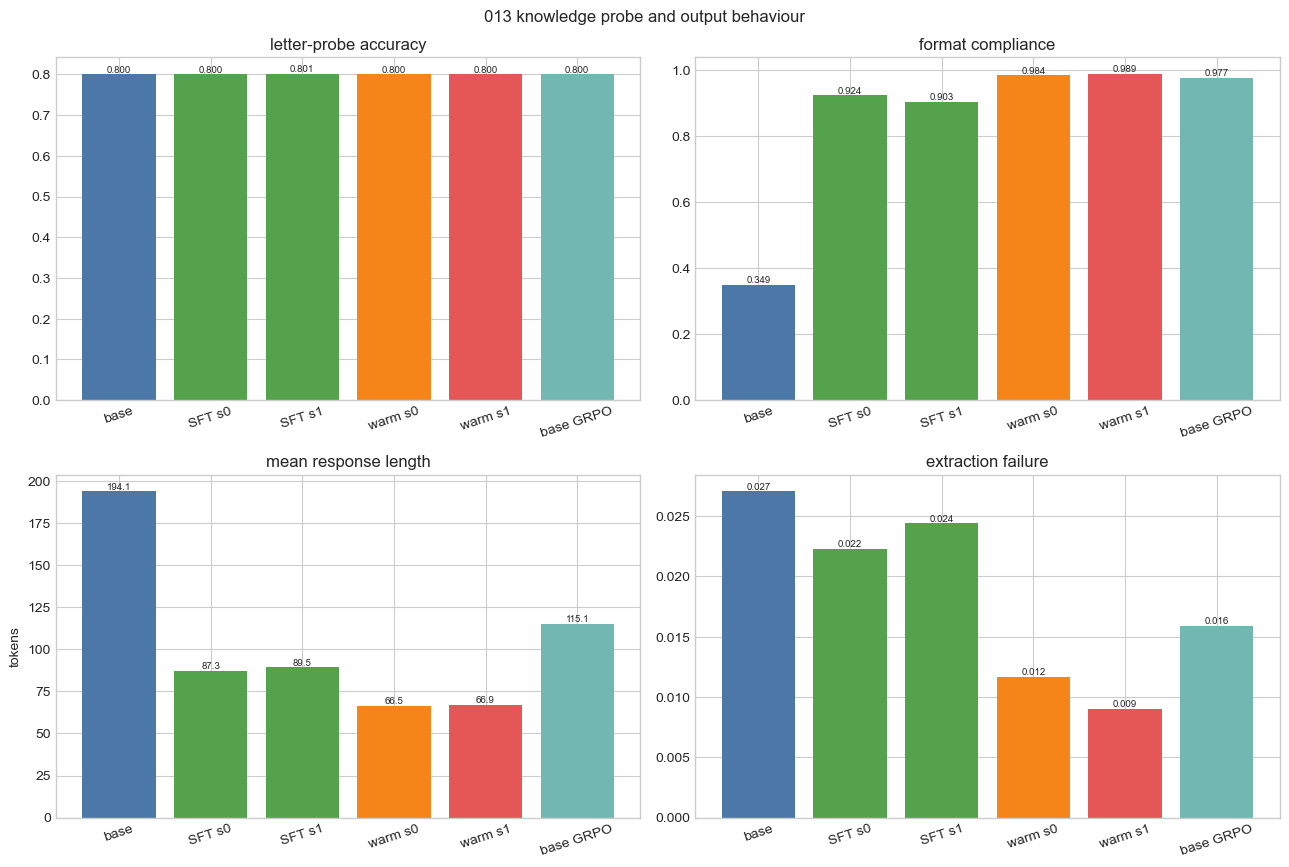

In [9]:
diagnostic_rows = []
diagnostic_specs = [
    ('base', WARM[0], 'base'),
    ('SFT seed 0', WARM[0], 'sft'),
    ('SFT seed 1', WARM[1], 'sft'),
    ('SFT + GRPO seed 0', WARM[0], 'grpo'),
    ('SFT + GRPO seed 1', WARM[1], 'grpo'),
    ('base + GRPO seed 0', BASE_ROUTE, 'grpo'),
]
for label, data, stage in diagnostic_specs:
    predictions = data['preds'][stage]
    diagnostic_rows.append({
        'condition': label,
        'generative accuracy': accuracy(predictions),
        'letter-probe accuracy': accuracy(data['lp_preds'][stage]),
        'format compliance': data['eval'][stage]['format_compliance'],
        'extraction failure': data['eval'][stage]['extraction_failure_rate'],
        'mean response length': data['eval'][stage]['mean_len'],
    })
diagnostics_tbl = pd.DataFrame(diagnostic_rows).set_index('condition')
display(diagnostics_tbl.round(4))

fig, axes = plt.subplots(2, 2, figsize=(13, 8.8))
metrics = [
    ('letter-probe accuracy', None),
    ('format compliance', None),
    ('mean response length', 'tokens'),
    ('extraction failure', None),
]
bar_colors = [
    COLORS['base'], COLORS['sft'], COLORS['sft'],
    COLORS['warm0'], COLORS['warm1'], COLORS['base_grpo'],
]
for ax, (metric, ylabel) in zip(axes.flat, metrics):
    values = diagnostics_tbl[metric].to_numpy()
    bars = ax.bar(np.arange(len(values)), values, color=bar_colors)
    for bar, value in zip(bars, values):
        label = f'{value:.1f}' if metric == 'mean response length' else f'{value:.3f}'
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            label,
            ha='center',
            va='bottom',
            fontsize=7,
        )
    ax.set_xticks(np.arange(len(values)))
    ax.set_xticklabels(
        ['base', 'SFT s0', 'SFT s1', 'warm s0', 'warm s1', 'base GRPO'],
        rotation=18,
    )
    ax.set_title(metric)
    if ylabel:
        ax.set_ylabel(ylabel)
fig.suptitle('013 knowledge probe and output behaviour')
fig.tight_layout()
save(fig, 'fig07_eval_diagnostics')
plt.show()


,tier,warm seed 0 gain,warm seed 1 gain,base route gain,warm minus base route
subject,,,,,
high_school_psychology,easy,0.0147,0.0183,0.0257,0.0055
marketing,easy,0.0000,-0.0043,0.0085,-0.0214
us_foreign_policy,easy,0.0200,0.0300,0.0100,0.0600
high_school_geography,medium,0.0505,0.0303,0.0354,-0.0051
philosophy,medium,0.0096,0.0289,0.0225,0.0354
business_ethics,medium,-0.0100,-0.0100,0.0300,-0.0200
high_school_mathematics,hard,0.0704,0.0667,0.0852,-0.0222
formal_logic,hard,0.0079,0.0476,0.0000,0.0000


saved fig08_subject_route_changes


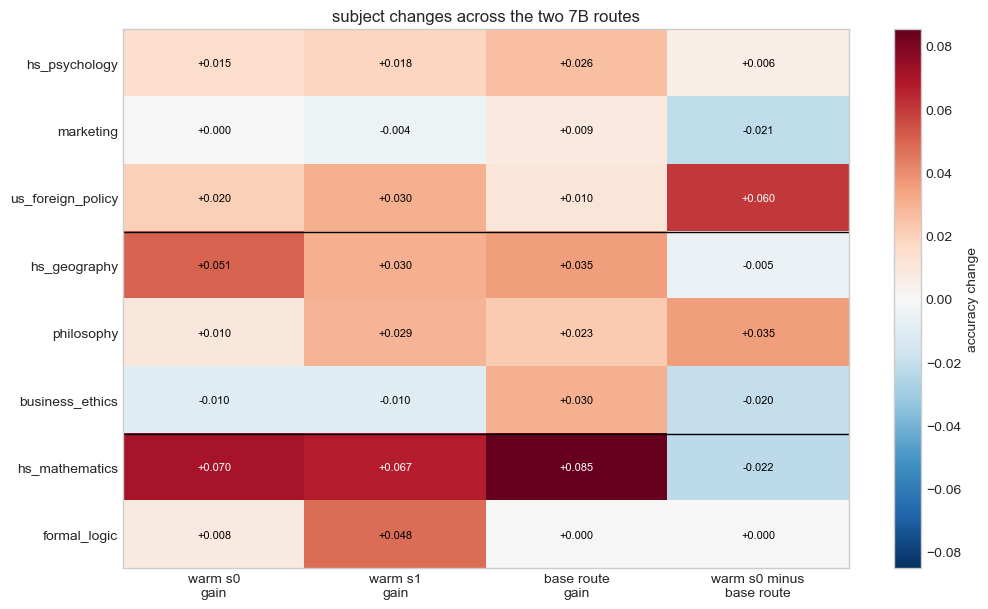

In [10]:
subject_rows = []
for subject in SUBJECTS:
    tier = TIER_LOOKUP[subject]
    row = {'subject': subject, 'tier': tier}
    row['warm seed 0 gain'] = (
        WARM[0]['eval']['grpo']['per_subject_acc'][subject]
        - WARM[0]['eval']['sft']['per_subject_acc'][subject]
    )
    row['warm seed 1 gain'] = (
        WARM[1]['eval']['grpo']['per_subject_acc'][subject]
        - WARM[1]['eval']['sft']['per_subject_acc'][subject]
    )
    row['base route gain'] = (
        BASE_ROUTE['eval']['grpo']['per_subject_acc'][subject]
        - BASE_ROUTE['eval']['base']['per_subject_acc'][subject]
    )
    row['warm minus base route'] = (
        WARM[0]['eval']['grpo']['per_subject_acc'][subject]
        - BASE_ROUTE['eval']['grpo']['per_subject_acc'][subject]
    )
    subject_rows.append(row)
subject_tbl = pd.DataFrame(subject_rows).set_index('subject')
display(subject_tbl.round(4))

heat_cols = ['warm seed 0 gain', 'warm seed 1 gain', 'base route gain', 'warm minus base route']
values = subject_tbl[heat_cols].to_numpy()
limit = max(abs(values.min()), abs(values.max()))
fig, ax = plt.subplots(figsize=(10.5, 6.2))
image = ax.imshow(
    values,
    cmap='RdBu_r',
    norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
    aspect='auto',
    interpolation='nearest',
)
ax.grid(False)
for row in range(values.shape[0]):
    for col in range(values.shape[1]):
        color = heatmap_text_color(image, values[row, col])
        ax.text(col, row, f'{values[row, col]:+.3f}', ha='center', va='center', fontsize=8, color=color)
ax.set_xticks(np.arange(len(heat_cols)))
ax.set_xticklabels(['warm s0\ngain', 'warm s1\ngain', 'base route\ngain', 'warm s0 minus\nbase route'])
ax.set_yticks(np.arange(len(subject_tbl)))
ax.set_yticklabels([
    subject.replace('high_school_', 'hs_') for subject in subject_tbl.index
])
ax.axhline(2.5, color='black', lw=1)
ax.axhline(5.5, color='black', lw=1)
ax.set_title('subject changes across the two 7B routes')
fig.colorbar(image, ax=ax, label='accuracy change')
fig.tight_layout()
save(fig, 'fig08_subject_route_changes')
plt.show()


## 5. Cross-scale context

The direct route comparison uses matched seed 0 at each scale. The warm-route
primary curve uses every completed seed, with seed counts shown on the axis.
All included runs used an A100 and the frozen scientific protocol.


params_b  warm_grpo  warm_probe  warm_gain                    GPU
scale seed                                                                   
0.5B  0          0.5     0.4623      0.5679     0.2537  NVIDIA A100-SXM4-40GB
      1          0.5     0.3153      0.5626     0.0764  NVIDIA A100-SXM4-40GB
      2          0.5     0.5058      0.5600     0.2824  NVIDIA A100-SXM4-40GB
1.5B  0          1.5     0.6741      0.7001     0.1263  NVIDIA A100-SXM4-80GB
      1          1.5     0.6348      0.6980     0.1077  NVIDIA A100-SXM4-80GB
3B    0          3.0     0.7160      0.7410     0.1821  NVIDIA A100-SXM4-80GB
      1          3.0     0.7266      0.7447     0.2171  NVIDIA A100-SXM4-80GB
7B    0          7.0     0.8020      0.7999     0.0223  NVIDIA A100-SXM4-80GB
      1          7.0     0.8052      0.7999     0.0265  NVIDIA A100-SXM4-80GB

,params_b,n_warm_seeds,warm_mean,warm_min,warm_max,warm_probe_mean,warm_gain_mean,warm_seed0,warm_seed0_gain,base_grpo_seed0,base_grpo_gain,warm_minus_base_seed0,warm_GPU,base_GPU
scale,,,,,,,,,,,,,,
0.5B,0.5,3,0.4278,0.3153,0.5058,0.5635,0.2042,0.4623,0.2537,0.3992,0.2139,0.0632,NVIDIA A100-SXM4-40GB,NVIDIA A100-SXM4-40GB
1.5B,1.5,2,0.6545,0.6348,0.6741,0.6990,0.1170,0.6741,0.1263,0.6088,0.2378,0.0653,NVIDIA A100-SXM4-80GB,NVIDIA A100-SXM4-80GB
3B,3.0,2,0.7213,0.7160,0.7266,0.7428,0.1996,0.7160,0.1821,0.6768,0.0807,0.0393,NVIDIA A100-SXM4-80GB,NVIDIA A100-SXM4-80GB
7B,7.0,2,0.8036,0.8020,0.8052,0.7999,0.0244,0.8020,0.0223,0.7988,0.0303,0.0032,NVIDIA A100-SXM4-80GB,NVIDIA A100-SXM4-80GB


saved fig09_route_comparison_by_scale


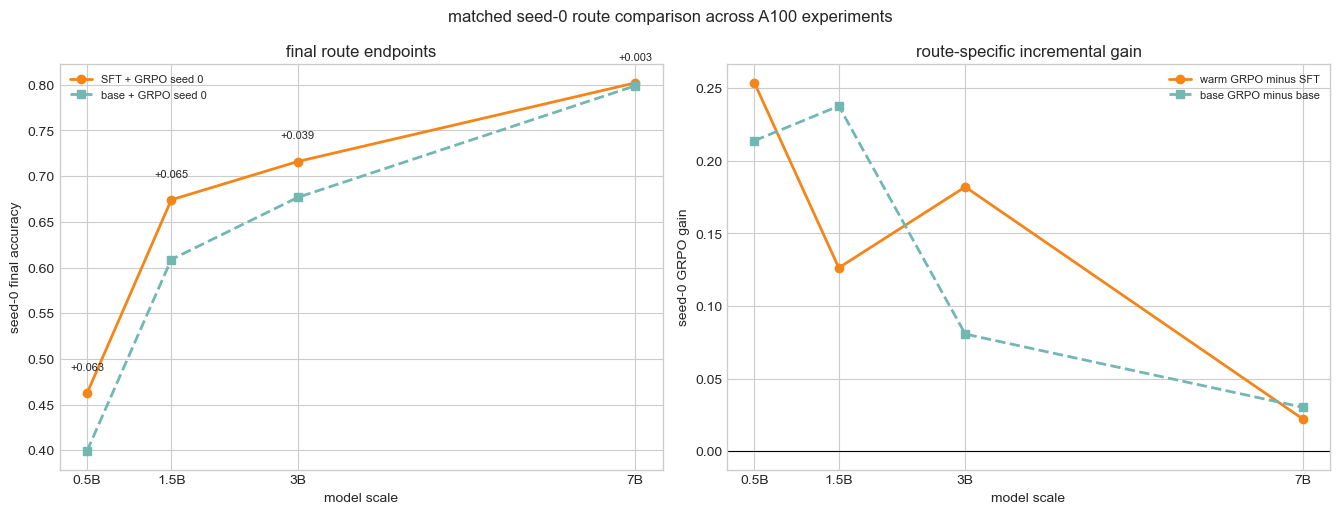

In [11]:
scale_seed_rows = []
scale_route_rows = []
for scale, spec in SCALE_SPECS.items():
    warm_values = []
    warm_probe_values = []
    warm_gain_values = []
    for seed in spec['warm_seeds']:
        warm_tag = (
            f"{spec['warm_exp']}_COLAB_FULL_{spec['code']}_"
            f'sft_grpo_seed{seed}'
        )
        run_dir = RES / warm_tag
        sft_rows = jsonl(run_dir / 'sft_preds.jsonl')
        grpo_rows = jsonl(run_dir / 'grpo_preds.jsonl')
        grpo_probe_rows = jsonl(run_dir / 'grpo_logprob_preds.jsonl')
        manifest = jload(run_dir / 'manifest.json')
        assert 'A100' in manifest['gpu']['device']
        warm_value = accuracy(grpo_rows)
        warm_values.append(warm_value)
        warm_probe_values.append(accuracy(grpo_probe_rows))
        warm_gain_values.append(warm_value - accuracy(sft_rows))
        scale_seed_rows.append({
            'scale': scale,
            'params_b': spec['params'],
            'seed': seed,
            'warm_grpo': warm_value,
            'warm_probe': accuracy(grpo_probe_rows),
            'warm_gain': warm_gain_values[-1],
            'GPU': manifest['gpu']['device'],
        })

    base_tag = (
        f"{spec['base_exp']}_COLAB_FULL_{spec['code']}_"
        'base_grpo_seed0'
    )
    base_dir = RES / base_tag
    base_eval_dir = RES / 'base_evals' / (
        f"{spec['base_exp']}_COLAB_FULL_{spec['code']}"
    )
    base_rows = jsonl(base_eval_dir / 'base_preds.jsonl')
    base_grpo_rows = jsonl(base_dir / 'grpo_preds.jsonl')
    base_manifest = jload(base_dir / 'manifest.json')
    assert 'A100' in base_manifest['gpu']['device']
    scale_route_rows.append({
        'scale': scale,
        'params_b': spec['params'],
        'n_warm_seeds': len(warm_values),
        'warm_mean': np.mean(warm_values),
        'warm_min': min(warm_values),
        'warm_max': max(warm_values),
        'warm_probe_mean': np.mean(warm_probe_values),
        'warm_gain_mean': np.mean(warm_gain_values),
        'warm_seed0': warm_values[0],
        'warm_seed0_gain': warm_gain_values[0],
        'base_grpo_seed0': accuracy(base_grpo_rows),
        'base_grpo_gain': accuracy(base_grpo_rows) - accuracy(base_rows),
        'warm_minus_base_seed0': warm_values[0] - accuracy(base_grpo_rows),
        'warm_GPU': scale_seed_rows[-1]['GPU'],
        'base_GPU': base_manifest['gpu']['device'],
    })

scale_seed_tbl = pd.DataFrame(scale_seed_rows)
scale_route_tbl = pd.DataFrame(scale_route_rows).sort_values('params_b').set_index('scale')
display(scale_seed_tbl.set_index(['scale', 'seed']).round(4))
display(scale_route_tbl.round(4))

x = scale_route_tbl['params_b'].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
axes[0].plot(x, scale_route_tbl['warm_seed0'], 'o-', color=COLORS['warm0'], lw=2, label='SFT + GRPO seed 0')
axes[0].plot(x, scale_route_tbl['base_grpo_seed0'], 's--', color=COLORS['base_grpo'], lw=2, label='base + GRPO seed 0')
for position, value in zip(x, scale_route_tbl['warm_minus_base_seed0']):
    axes[0].text(position, max(
        scale_route_tbl.loc[scale_route_tbl['params_b'] == position, 'warm_seed0'].iloc[0],
        scale_route_tbl.loc[scale_route_tbl['params_b'] == position, 'base_grpo_seed0'].iloc[0],
    ) + 0.025, f'{value:+.3f}', ha='center', fontsize=8)
axes[0].set_ylabel('seed-0 final accuracy')
axes[0].set_title('final route endpoints')
axes[0].legend(fontsize=8)

axes[1].plot(x, scale_route_tbl['warm_seed0_gain'], 'o-', color=COLORS['warm0'], lw=2, label='warm GRPO minus SFT')
axes[1].plot(x, scale_route_tbl['base_grpo_gain'], 's--', color=COLORS['base_grpo'], lw=2, label='base GRPO minus base')
axes[1].axhline(0, color='black', lw=0.8)
axes[1].set_ylabel('seed-0 GRPO gain')
axes[1].set_title('route-specific incremental gain')
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(scale_route_tbl.index)
    ax.set_xlabel('model scale')
fig.suptitle('matched seed-0 route comparison across A100 experiments')
fig.tight_layout()
save(fig, 'fig09_route_comparison_by_scale')
plt.show()


saved fig10_completed_scale_curve


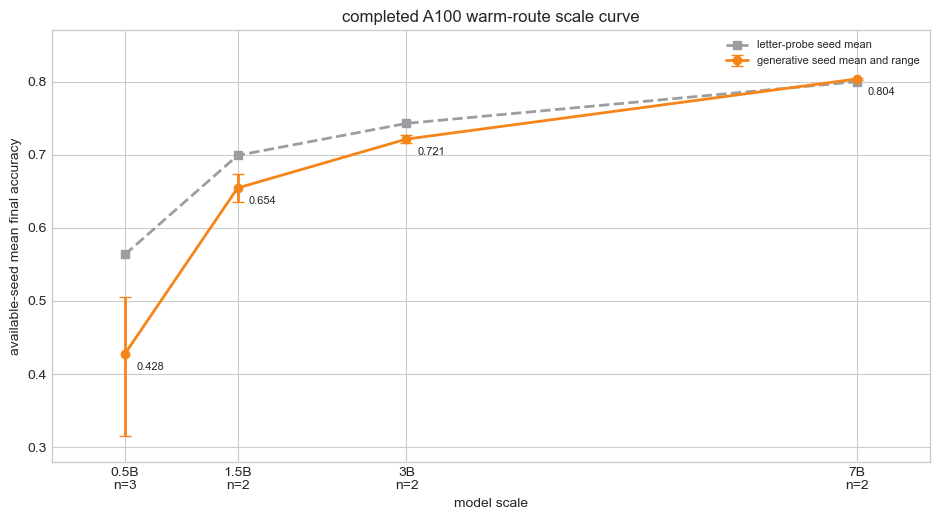

In [12]:
fig, ax = plt.subplots(figsize=(9.5, 5.3))
x = scale_route_tbl['params_b'].to_numpy()
warm_mean = scale_route_tbl['warm_mean'].to_numpy()
warm_low = warm_mean - scale_route_tbl['warm_min'].to_numpy()
warm_high = scale_route_tbl['warm_max'].to_numpy() - warm_mean
ax.errorbar(
    x,
    warm_mean,
    yerr=[warm_low, warm_high],
    marker='o',
    lw=2,
    capsize=4,
    color=COLORS['warm0'],
    label='generative seed mean and range',
)
ax.plot(
    x,
    scale_route_tbl['warm_probe_mean'],
    's--',
    color=COLORS['probe'],
    lw=2,
    label='letter-probe seed mean',
)
for position, value in zip(x, warm_mean):
    ax.annotate(f'{value:.3f}', (position, value), xytext=(8, -6),
                textcoords='offset points', ha='left', va='top', fontsize=8)
ax.margins(x=0.1)
ax.set_xticks(x)
ax.set_xticklabels([
    f'{scale}\nn={int(scale_route_tbl.loc[scale, "n_warm_seeds"])}'
    for scale in scale_route_tbl.index
])
ax.set_xlabel('model scale')
ax.set_ylabel('available-seed mean final accuracy')
ax.set_ylim(0.28, 0.87)
ax.set_title('completed A100 warm-route scale curve')
ax.legend(fontsize=8)
fig.tight_layout()
save(fig, 'fig10_completed_scale_curve')
plt.show()


## 6. Compute and exact tables


,SFT train,SFT eval,GRPO train,GRPO eval,probes,peak VRAM GB,total recorded hours
run,,,,,,,
SFT + GRPO seed 1,0.271,0.739,2.864,0.524,0.023,71.317,4.420
base + GRPO seed 0,0.000,0.000,3.753,0.694,0.011,73.433,4.458


saved fig11_phase2_compute


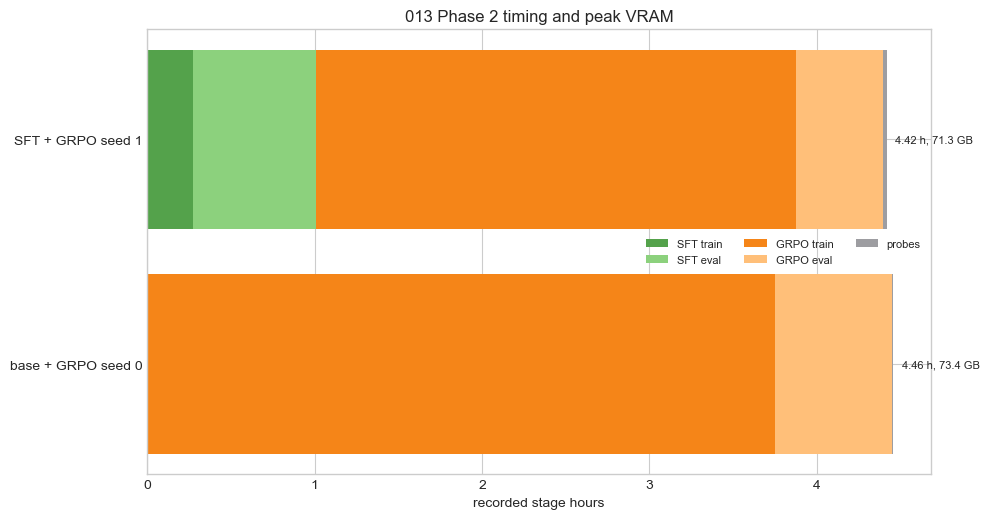

the positive Phase 2 compute-unit record is not closed in the pulled results


,ts_start,notebook,colab_cu_before,unit_rate
session_id,,,,
20260723_084117,2026-07-23 08:41,013_colab_7b_phase2,165.87,6.77


In [13]:
compute_rows = []
for label, data in [
    ('SFT + GRPO seed 1', WARM[1]),
    ('base + GRPO seed 0', BASE_ROUTE),
]:
    timings = data['man']['timings_sec']
    compute_rows.append({
        'run': label,
        'SFT train': timings.get('sft_train', 0) / 3600,
        'SFT eval': timings.get('sft_eval', 0) / 3600,
        'GRPO train': timings.get('grpo_train', 0) / 3600,
        'GRPO eval': timings.get('grpo_eval', 0) / 3600,
        'probes': (
            timings.get('sft_logprob_eval', 0)
            + timings.get('grpo_logprob_eval', 0)
        ) / 3600,
        'peak VRAM GB': data['man']['gpu']['peak_vram_gb'],
    })
compute_tbl = pd.DataFrame(compute_rows).set_index('run')
compute_tbl['total recorded hours'] = compute_tbl[
    ['SFT train', 'SFT eval', 'GRPO train', 'GRPO eval', 'probes']
].sum(axis=1)
display(compute_tbl.round(3))

fig, ax = plt.subplots(figsize=(10, 5.3))
parts = ['SFT train', 'SFT eval', 'GRPO train', 'GRPO eval', 'probes']
part_colors = ['#54A24B', '#8CD17D', '#F58518', '#FFBF79', '#9D9DA1']
left = np.zeros(len(compute_tbl))
for part, color in zip(parts, part_colors):
    values = compute_tbl[part].to_numpy()
    ax.barh(np.arange(len(compute_tbl)), values, left=left, color=color, label=part)
    left += values
for position, (total, vram) in enumerate(zip(
    compute_tbl['total recorded hours'],
    compute_tbl['peak VRAM GB'],
)):
    ax.text(total + 0.05, position, f'{total:.2f} h, {vram:.1f} GB', va='center', fontsize=8)
ax.set_yticks(np.arange(len(compute_tbl)))
ax.set_yticklabels(compute_tbl.index)
ax.invert_yaxis()
ax.set_xlabel('recorded stage hours')
ax.set_title('013 Phase 2 timing and peak VRAM')
ax.legend(fontsize=8, ncol=3)
fig.tight_layout()
save(fig, 'fig11_phase2_compute')
plt.show()

unit_rows = raw_jsonl(RES / 'colab_units.jsonl')
phase2_units = [
    row for row in unit_rows
    if row.get('notebook') == '013_colab_7b_phase2'
    and row.get('colab_cu_used', 0) > 0
]
open_unit_files = sorted((RES / 'open_cu_sessions').glob('*.json'))
open_phase2_units = [
    jload(path) for path in open_unit_files
    if jload(path).get('notebook') == '013_colab_7b_phase2'
]
if phase2_units:
    unit_tbl = pd.DataFrame(phase2_units).set_index('session_id')
    display(unit_tbl)
else:
    unit_tbl = pd.DataFrame()
    print('the positive Phase 2 compute-unit record is not closed in the pulled results')
    if open_phase2_units:
        display(pd.DataFrame(open_phase2_units).set_index('session_id'))


In [14]:
# keep the exact values used by the plots in compact tables
display(endpoint_tbl.set_index(['group', 'condition']).round(6))
display(paired_tbl.round(6))
display(route_stats_tbl.round(6))
display(diagnostics_tbl.round(6))
display(subject_tbl.round(6))
display(scale_route_tbl.round(6))
display(compute_tbl.round(4))


mean       min       max  n
group   condition                                   
easy    base         0.869170  0.869170  0.869170  1
        GSM8K SFT    0.879977  0.878271  0.881684  2
        SFT + GRPO   0.892491  0.891923  0.893060  2
        base + GRPO  0.888510  0.888510  0.888510  1
medium  base         0.735632  0.735632  0.735632  1
        GSM8K SFT    0.755337  0.753695  0.756979  2
        SFT + GRPO   0.776683  0.776683  0.776683  2
        base + GRPO  0.763547  0.763547  0.763547  1
hard    base         0.595960  0.595960  0.595960  1
        GSM8K SFT    0.592172  0.588384  0.595960  2
        SFT + GRPO   0.647727  0.638889  0.656566  2
        base + GRPO  0.654040  0.654040  0.654040  1
overall base         0.768577  0.768577  0.768577  1
        GSM8K SFT    0.779193  0.778662  0.779724  2
        SFT + GRPO   0.803609  0.802017  0.805202  2
        base + GRPO  0.798832  0.798832  0.798832  1

delta     ci_lo     ci_hi  \
run                group                                   
SFT + GRPO seed 0  easy     0.011377 -0.004551  0.027304   
                   medium   0.019704 -0.003284  0.041051   
                   hard     0.050505  0.002525  0.098485   
                   overall  0.022293  0.007962  0.036624   
SFT + GRPO seed 1  easy     0.013652 -0.001138  0.028441   
                   medium   0.022989  0.001642  0.044335   
                   hard     0.060606  0.015152  0.108586   
                   overall  0.026539  0.012739  0.040340   
base + GRPO seed 0 easy     0.019340  0.001138  0.038680   
                   medium   0.027915 -0.001642  0.057471   
                   hard     0.058081  0.010101  0.106061   
                   overall  0.030255  0.013800  0.046709   

                            reference_only_correct  grpo_only_correct  \
run                group                                                
SFT + GRPO seed 0  easy                         19                 29   
                   medium                       18                 30   
                   hard                         38                 58   
                   overall                      75                117   
SFT + GRPO seed 1  easy                         16                 28   
                   medium                       16                 30   
                   hard                         33                 57   
                   overall                      65                115   
base + GRPO seed 0 easy                         28                 45   
                   medium                       36                 53   
                   hard                         35                 58   
                   overall                      99                156   

                            mcnemar_p  holm_p_tiers  
run                group                             
SFT + GRPO seed 0  easy      0.193413      0.222806  
                   medium    0.111403      0.222806  
                   hard      0.051911      0.155732  
                   overall   0.002987           NaN  
SFT + GRPO seed 1  easy      0.096142      0.108152  
                   medium    0.054076      0.108152  
                   hard      0.014867      0.044600  
                   overall   0.000239           NaN  
base + GRPO seed 0 easy      0.060370      0.120740  
                   medium    0.089321      0.120740  
                   hard      0.022019      0.066056  
                   overall   0.000431           NaN

,delta,ci_lo,ci_hi,reference_only_correct,grpo_only_correct,mcnemar_p,holm_p_tiers
group,,,,,,,
easy,0.004551,-0.012514,0.021615,29,33,0.703537,1.0
medium,0.013136,-0.016420,0.042693,40,48,0.455741,1.0
hard,-0.015152,-0.068182,0.037879,63,57,0.648260,1.0
overall,0.003185,-0.013800,0.020170,132,138,0.760972,NaN


,generative accuracy,letter-probe accuracy,format compliance,extraction failure,mean response length
condition,,,,,
base,0.768577,0.800425,0.349257,0.027070,194.074841
SFT seed 0,0.779724,0.800425,0.923567,0.022293,87.280786
SFT seed 1,0.778662,0.801486,0.903397,0.024416,89.474522
SFT + GRPO seed 0,0.802017,0.799894,0.984076,0.011677,66.451168
SFT + GRPO seed 1,0.805202,0.799894,0.988854,0.009023,66.913482
base + GRPO seed 0,0.798832,0.799894,0.976645,0.015924,115.074310


,tier,warm seed 0 gain,warm seed 1 gain,base route gain,warm minus base route
subject,,,,,
high_school_psychology,easy,0.014679,0.018349,0.025688,0.005505
marketing,easy,0.000000,-0.004274,0.008547,-0.021368
us_foreign_policy,easy,0.020000,0.030000,0.010000,0.060000
high_school_geography,medium,0.050505,0.030303,0.035354,-0.005051
philosophy,medium,0.009646,0.028939,0.022508,0.035370
business_ethics,medium,-0.010000,-0.010000,0.030000,-0.020000
high_school_mathematics,hard,0.070370,0.066667,0.085185,-0.022222
formal_logic,hard,0.007937,0.047619,0.000000,0.000000


,params_b,n_warm_seeds,warm_mean,warm_min,warm_max,warm_probe_mean,warm_gain_mean,warm_seed0,warm_seed0_gain,base_grpo_seed0,base_grpo_gain,warm_minus_base_seed0,warm_GPU,base_GPU
scale,,,,,,,,,,,,,,
0.5B,0.5,3,0.427813,0.315287,0.505839,0.563517,0.204176,0.462314,0.253715,0.399151,0.213907,0.063163,NVIDIA A100-SXM4-40GB,NVIDIA A100-SXM4-40GB
1.5B,1.5,2,0.654459,0.634820,0.674098,0.699045,0.117038,0.674098,0.126327,0.608811,0.237792,0.065287,NVIDIA A100-SXM4-80GB,NVIDIA A100-SXM4-80GB
3B,3.0,2,0.721338,0.716030,0.726645,0.742834,0.199575,0.716030,0.182059,0.676752,0.080679,0.039278,NVIDIA A100-SXM4-80GB,NVIDIA A100-SXM4-80GB
7B,7.0,2,0.803609,0.802017,0.805202,0.799894,0.024416,0.802017,0.022293,0.798832,0.030255,0.003185,NVIDIA A100-SXM4-80GB,NVIDIA A100-SXM4-80GB


,SFT train,SFT eval,GRPO train,GRPO eval,probes,peak VRAM GB,total recorded hours
run,,,,,,,
SFT + GRPO seed 1,0.2706,0.7389,2.8640,0.5238,0.0228,71.317,4.4202
base + GRPO seed 0,0.0000,0.0000,3.7534,0.6940,0.0106,73.433,4.4579


## Cross-referenced conclusion

All three 013 runs finished normally on the A100 80GB in BF16. Every GRPO run
reached 500 steps and every evaluation has 1,884 items. No OOM, fallback or
non-finite values were found. The seed-1 warm run used 71.3 GB peak VRAM and the
base route used 73.4 GB.

The registered 7B SFT-to-GRPO endpoint is now complete across two seeds. Final
accuracy is 80.20% and 80.52%, giving a mean of 80.36% and a range of only 0.32
points. The mean SFT result is 77.92%, so the mean incremental GRPO gain is 2.44
points. The paired changes are +2.23 points for seed 0 and +2.65 points for seed
1, with McNemar p = .0030 and p = .00024. The mean easy, medium and hard gains
are +1.25, +2.13 and +5.56 points. Both seeds therefore keep the same ordering,
with the largest change in the hard tier.

Base-to-GRPO reaches 79.88%, compared with 76.86% at base. Its paired gain is
+3.03 points, with p = .00043. The matched seed-0 difference between the final
warm and base routes is only +0.32 points, with a 95% interval from -1.38 to
+2.02 points and p = .761. This gives no evidence of an overall accuracy
advantage from the GSM8K warm start at 7B, but the method comparison still has
only one matched seed. The warm route produces much shorter answers, about 66
to 67 tokens instead of 115, and slightly higher format compliance.

The completed A100 warm-route means are 42.78%, 65.45%, 72.13% and 80.36% from
0.5B to 7B. The incremental GRPO gains are 20.42, 11.70, 19.96 and 2.44 points,
so the gain still does not form a smooth scale curve. In the matched seed-0
route comparison, the warm-route advantage over base-to-GRPO falls from 6.32,
6.53 and 3.93 points at the smaller scales to 0.32 points at 7B. This is a
descriptive one-seed route pattern, not a final interaction test.

The scientific artifacts are complete. The pulled compute-unit files still
contain the main Phase 2 session as an open record, so the final unit total
should be taken from the closing cell after it is synced.
